Importing Libraries

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


Plot Style

In [17]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

Load Dataset

In [18]:
df = pd.read_csv("50_Startups.csv")
print(df.head())

   R&D Spend  Administration  Marketing Spend     Profit
0  165349.20       136897.80        471784.10  192261.83
1  162597.70       151377.59        443898.53  191792.06
2  153441.51       101145.55        407934.54  191050.39
3  144372.41       118671.85        383199.62  182901.99
4  142107.34        91391.77        366168.42  166187.94


Data Exploration

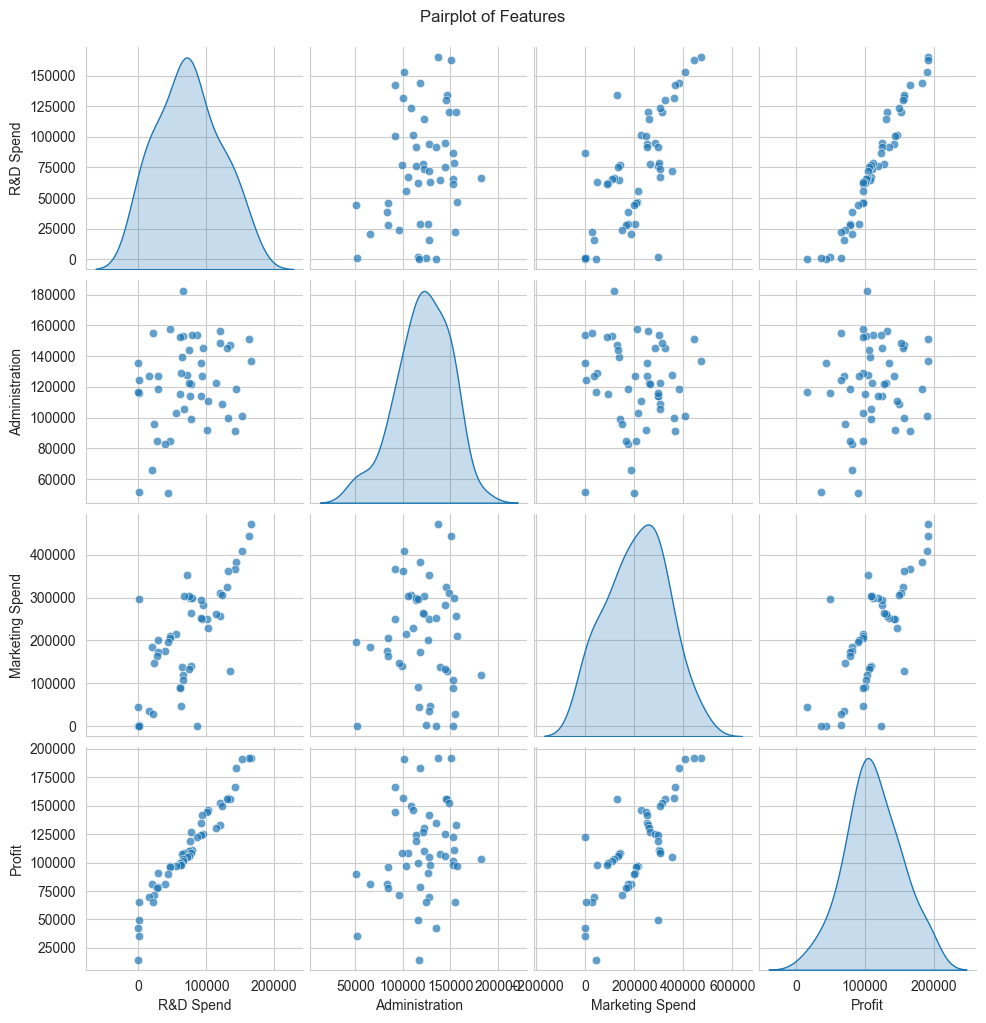

In [19]:
sns.pairplot(df, diag_kind="kde", plot_kws={"alpha":0.7})
plt.suptitle("Pairplot of Features", y=1.02)
plt.show()

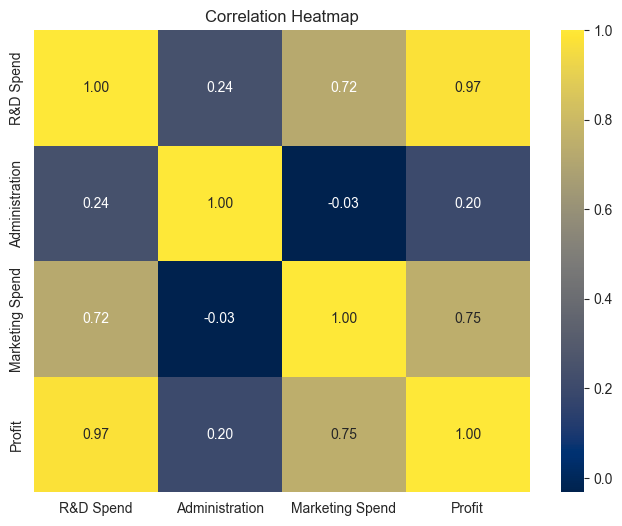

In [20]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap="cividis", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

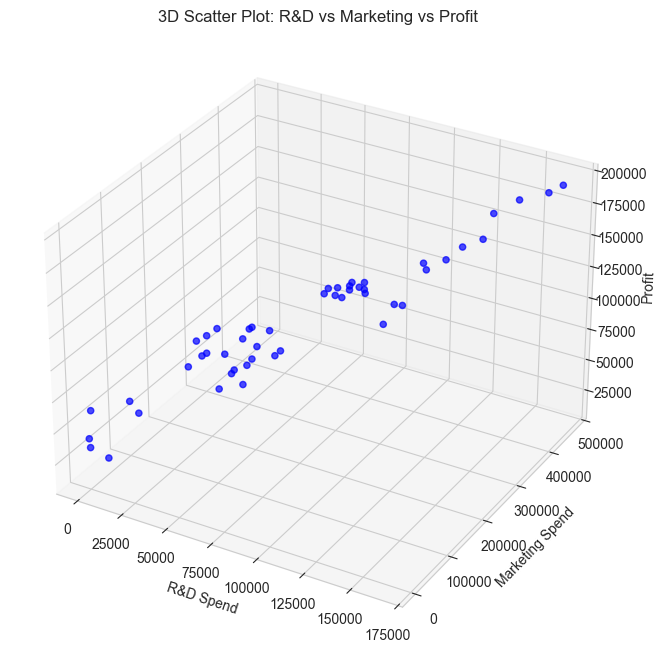

In [21]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(df["R&D Spend"], df["Marketing Spend"], df["Profit"], c="blue", marker="o", alpha=0.7)
ax.set_xlabel("R&D Spend")
ax.set_ylabel("Marketing Spend")
ax.set_zlabel("Profit")
ax.set_title("3D Scatter Plot: R&D vs Marketing vs Profit")
plt.show()

Prepare Data

In [22]:
X = df.drop("Profit", axis=1)
y = df["Profit"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


Define Models

In [23]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

Train & Evaluate Models

In [24]:
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[name] = {
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred)
    }

results_df = pd.DataFrame(results).T
best_model_name = results_df["R2"].idxmax()
print("\nModel Performance:\n", results_df)
print(f"\n Best Model: {best_model_name}")



Model Performance:
                             MSE         RMSE          MAE        R2
Linear Regression  8.092632e+07  8995.905803  6979.152252  0.900065
Ridge Regression   8.092632e+07  8995.905803  6979.152252  0.900065
Lasso Regression   8.092632e+07  8995.905803  6979.152252  0.900065
Random Forest      7.262501e+07  8522.030780  6437.497740  0.910316
Gradient Boosting  8.867477e+07  9416.728084  8664.903403  0.890497

 Best Model: Random Forest


Compare Models Visually

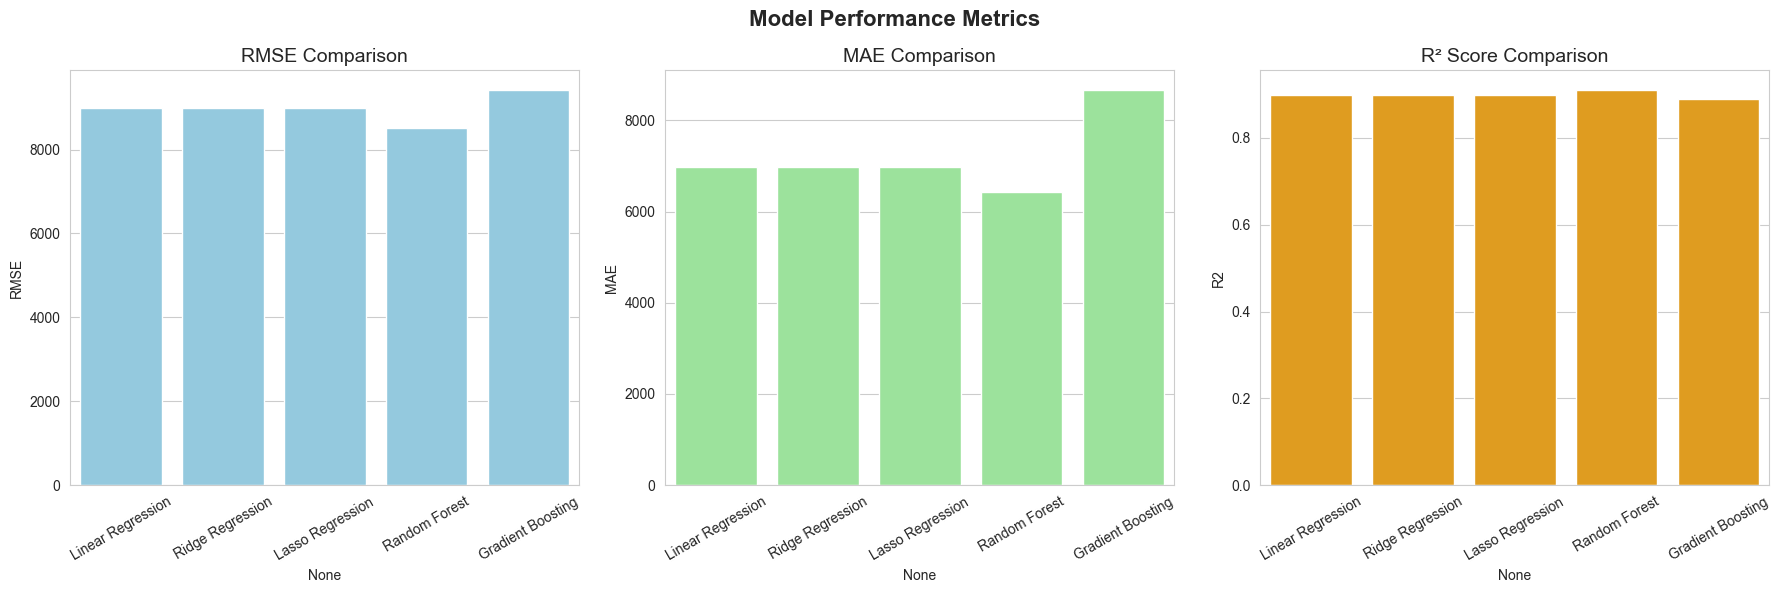

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18,6))

sns.barplot(x=results_df.index, y=results_df["RMSE"], ax=axes[0], color="skyblue")
axes[0].set_title("RMSE Comparison", fontsize=14)
axes[0].tick_params(axis='x', rotation=30)

sns.barplot(x=results_df.index, y=results_df["MAE"], ax=axes[1], color="lightgreen")
axes[1].set_title("MAE Comparison", fontsize=14)
axes[1].tick_params(axis='x', rotation=30)

sns.barplot(x=results_df.index, y=results_df["R2"], ax=axes[2], color="orange")
axes[2].set_title("R² Score Comparison", fontsize=14)
axes[2].tick_params(axis='x', rotation=30)

plt.suptitle("Model Performance Metrics", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

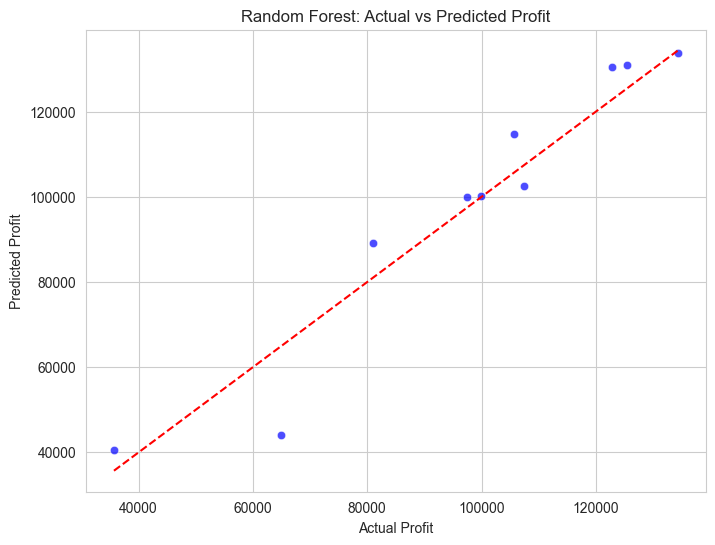

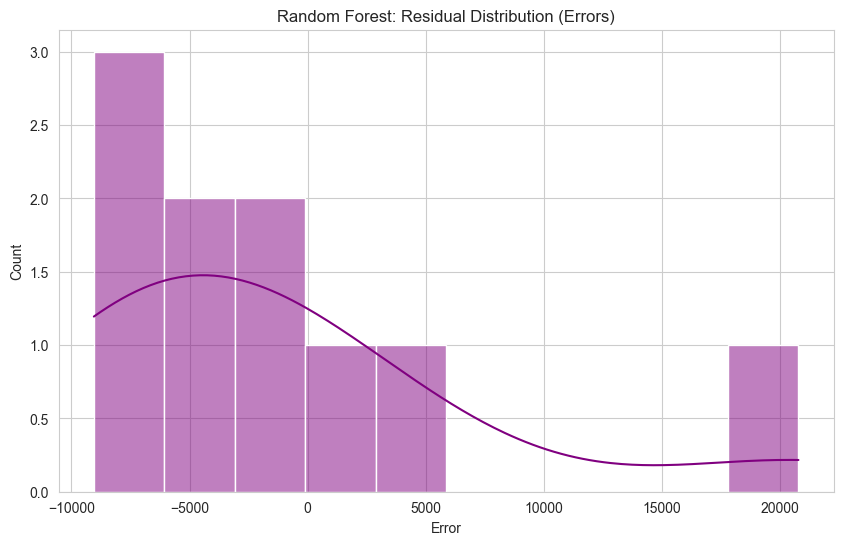

In [26]:
best_model = models[best_model_name]
y_pred_best = best_model.predict(X_test)

# Actual vs Predicted
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=y_pred_best, color="blue", alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.title(f"{best_model_name}: Actual vs Predicted Profit")
plt.show()

# Residuals
residuals = y_test - y_pred_best
sns.histplot(residuals, kde=True, color="purple", bins=10)
plt.title(f"{best_model_name}: Residual Distribution (Errors)")
plt.xlabel("Error")
plt.show()

3D Regression Plane

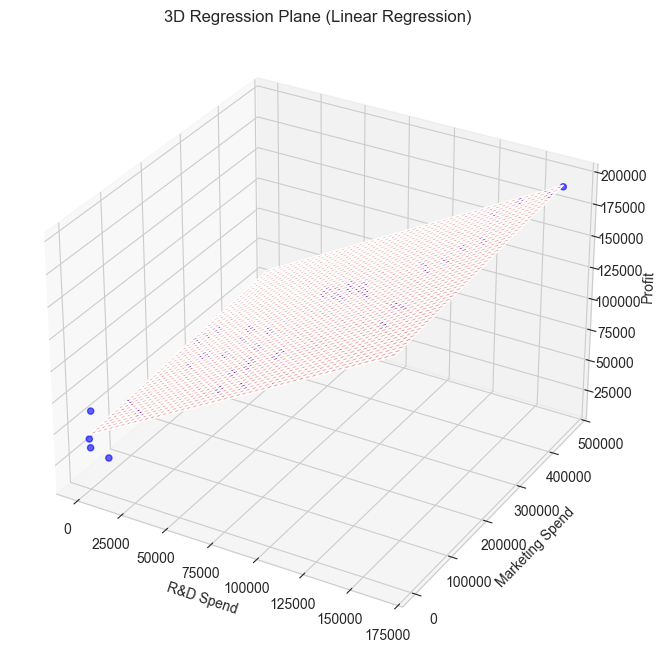

In [27]:
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)

x_surf, y_surf = np.meshgrid(np.linspace(X["R&D Spend"].min(), X["R&D Spend"].max(), 50),
                             np.linspace(X["Marketing Spend"].min(), X["Marketing Spend"].max(), 50))

z_surf = lin_model.intercept_ + lin_model.coef_[0]*x_surf + lin_model.coef_[2]*y_surf + lin_model.coef_[1]*X["Administration"].mean()

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X["R&D Spend"], X["Marketing Spend"], y, c="blue", alpha=0.6, marker="o")
ax.plot_surface(x_surf, y_surf, z_surf, color="red", alpha=0.3)
ax.set_xlabel("R&D Spend")
ax.set_ylabel("Marketing Spend")
ax.set_zlabel("Profit")
ax.set_title("3D Regression Plane (Linear Regression)")
plt.show()

version
matplotlib                3.10.0
numpy                     2.2.1
pandas                    2.2.3
seaborn                   0.13.2
scikit-learn              1.7.1


In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load dataset
data = pd.read_csv("50_Startups.csv")

# Features
X = data[['R&D Spend', 'Administration', 'Marketing Spend']]

# Target
y = data['Profit']

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
print("MSE :", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("R2  :", r2_score(y_test, y_pred))

MSE : 72625008.62306513
RMSE: 8522.030780457504
MAE : 6437.497739999977
R2  : 0.9103164738430438


In [5]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor

# -----------------------------
# Read CSV File
# -----------------------------
data = pd.read_csv("50_Startups.csv")

# -----------------------------
# Create Profit Column
# -----------------------------
# Artificial profit generation for training

data['Profit'] = (
    data['R&D Spend'] * 0.7 +
    data['Marketing Spend'] * 0.3 -
    data['Administration'] * 0.1 +
    np.random.randint(-10000, 10000, size=len(data))
)

# -----------------------------
# Features and Target
# -----------------------------
X = data[['R&D Spend', 'Administration', 'Marketing Spend']]

y = data['Profit']

# -----------------------------
# Train Random Forest Model
# -----------------------------
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X, y)

# -----------------------------
# Predict Profit for all 50 companies
# -----------------------------
predicted_profit = model.predict(X)

# -----------------------------
# Add Predicted Profit Column
# -----------------------------
data['Predicted Profit'] = predicted_profit

# -----------------------------
# Display All 50 Companies Profit
# -----------------------------
print("\nPredicted Profit of 50 Companies:\n")

for i in range(len(data)):
    print(f"Company {i+1} : ₹{predicted_profit[i]:.2f}")

# -----------------------------
# Save Output CSV
# -----------------------------
data.to_csv("50_company_profit_prediction.csv", index=False)

print("\nFile saved successfully!")


Predicted Profit of 50 Companies:

Company 1 : ₹234727.58
Company 2 : ₹233786.21
Company 3 : ₹216608.21
Company 4 : ₹202308.06
Company 5 : ₹200541.22
Company 6 : ₹186977.56
Company 7 : ₹112370.81
Company 8 : ₹177737.27
Company 9 : ₹157064.52
Company 10 : ₹154591.49
Company 11 : ₹125403.38
Company 12 : ₹139579.03
Company 13 : ₹128515.87
Company 14 : ₹128026.45
Company 15 : ₹139715.45
Company 16 : ₹136488.34
Company 17 : ₹123578.11
Company 18 : ₹137963.96
Company 19 : ₹143483.41
Company 20 : ₹52409.52
Company 21 : ₹136626.57
Company 22 : ₹133768.54
Company 23 : ₹126244.53
Company 24 : ₹133925.56
Company 25 : ₹83109.29
Company 26 : ₹66228.19
Company 27 : ₹84912.28
Company 28 : ₹152527.02
Company 29 : ₹64331.41
Company 30 : ₹61251.94
Company 31 : ₹57813.95
Company 32 : ₹58330.29
Company 33 : ₹37339.18
Company 34 : ₹84194.48
Company 35 : ₹78021.97
Company 36 : ₹84457.75
Company 37 : ₹68954.34
Company 38 : ₹81385.18
Company 39 : ₹57673.27
Company 40 : ₹66628.05
Company 41 : ₹65189.67
Compan